# Task 1 — Error audit of the selected LightGBM

This is an **analysis-only notebook**, not a dataset builder. It reads the saved `eda_combined_v1` train split and the two existing Round 4 out-of-fold (OOF) prediction files for the 38-feature LightGBM procedure selected in Round 3. It does not fit a model, inspect Test, create features, or call `save_data`.

The saved full-data model was fitted on all labeled rows, so its predictions on those rows would be in-sample. The OOF predictions below are the appropriate source for error analysis. Each repeat covers the same accounts once; use repeat 1 for the main figures and repeat 2 only to check whether patterns persist. All slice findings are descriptive and exploratory.

In [1]:
from pathlib import Path
import json
import sys

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "src" / "pipeline" / "save_data.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.pipeline.random_seed import set_seed
SEED = set_seed()

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.metrics import confusion_matrix, fbeta_score

sns.set_theme(style="whitegrid", context="notebook")
SRC = ROOT / "src"
TASK = SRC / "task1"
MODEL_NAME = "t1_lgbm_combined_pruned_cv6_full_v1"
OOF_STEM = "round4_lgbm_combined_pruned"
TARGET, ID = "is_cheater", "player_id"

model_card = json.loads((TASK / "save" / f"{MODEL_NAME}.json").read_text(encoding="utf-8"))
data_name = model_card["data_name"]
data_card = json.loads((TASK / "data" / "eda" / f"{data_name}.json").read_text(encoding="utf-8"))
assert data_name == "eda_combined_v1"
assert model_card["data_card_path"] == f"task1/data/eda/{data_name}.json"
train = pd.read_parquet(SRC / data_card["splits"]["train"]["path"])
assert len(train) == data_card["splits"]["train"]["rows"]
assert train[ID].is_unique and train[TARGET].notna().all()
print(f"Dataset: {data_name}; labeled accounts: {len(train):,}")
print(f"Selected model: {MODEL_NAME}; outer-CV mean macro F2: {model_card['card']['outer_cv_mean_macro_F2']:.5f}")

Dataset: eda_combined_v1; labeled accounts: 90,816
Selected model: t1_lgbm_combined_pruned_cv6_full_v1; outer-CV mean macro F2: 0.77733


## 1. Load and verify held-out predictions

The OOF files were made with three outer folds per repeat and fold-local threshold tuning. The saved full-data model is used here only to identify the selected procedure and its dataset lineage.

In [2]:
def load_oof(repeat):
    suffix = "" if repeat == 1 else f"_repeat{repeat}"
    stem = f"{OOF_STEM}{suffix}_oof_v1"
    base = TASK / "models" / "results"
    card = json.loads((base / f"{stem}.json").read_text(encoding="utf-8"))
    frame = pd.read_parquet(base / f"{stem}.parquet")
    key = card["key"]
    assert key["data_name"] == data_name
    assert key["data_created_at"] == data_card["created_at"]
    assert key["selected_features"] == model_card["card"]["selected_features"]
    assert key["source"] == model_card["card"]["source_model"]
    assert len(frame) == card["rows"] == len(train)
    assert frame["row_index"].is_unique
    frame = frame.sort_values("row_index").reset_index(drop=True)
    assert np.array_equal(frame["row_index"].to_numpy(), np.arange(len(train)))
    assert frame[ID].equals(train[ID].reset_index(drop=True))
    assert frame["true"].equals(train[TARGET].astype(int).reset_index(drop=True))
    assert frame["prob"].between(0, 1).all()
    assert frame["pred"].isin([0, 1]).all()
    assert (frame["pred"] == (frame["prob"] >= frame["threshold"]).astype(int)).all()
    assert frame["fold"].nunique() == 3
    frame["repeat"] = repeat
    frame["error_type"] = np.select(
        [(frame.true == 0) & (frame.pred == 0),
         (frame.true == 0) & (frame.pred == 1),
         (frame.true == 1) & (frame.pred == 0),
         (frame.true == 1) & (frame.pred == 1)],
        ["TN", "FP", "FN", "TP"], default="unknown")
    assert not (frame.error_type == "unknown").any()
    frame["margin"] = frame["prob"] - frame["threshold"]
    return frame

oof1, oof2 = load_oof(1), load_oof(2)
scores = []
for frame in (oof1, oof2):
    for fold, group in frame.groupby("fold"):
        scores.append({"repeat": int(frame.repeat.iloc[0]), "fold": int(fold),
                       "rows": len(group), "threshold": group.threshold.iloc[0],
                       "macro_F2": fbeta_score(group.true, group.pred, beta=2,
                                               average="macro", zero_division=0)})
scores = pd.DataFrame(scores)
display(scores.round(5))
print("Six-fold mean macro F2:", round(scores.macro_F2.mean(), 5))
assert abs(scores.macro_F2.mean() - model_card["card"]["outer_cv_mean_macro_F2"]) < 1e-10

,repeat,fold,rows,threshold,macro_F2
0,1,1,30272,0.400,0.77831
1,1,2,30272,0.400,0.77765
2,1,3,30272,0.375,0.77723
3,2,4,30272,0.400,0.77484
4,2,5,30272,0.375,0.77799
5,2,6,30272,0.375,0.77795


Six-fold mean macro F2: 0.77733


## 2. How many errors, and which class suffers?

The confusion matrix and error rates use **repeat 1 only**. False positive means a legitimate account predicted as a cheater; false negative means a cheater missed by the model.

,accounts
error_type,
TN,47245
FP,11846
FN,7470
TP,24255


False-positive rate among legitimate: 20.05%
False-negative rate among cheaters: 23.55%


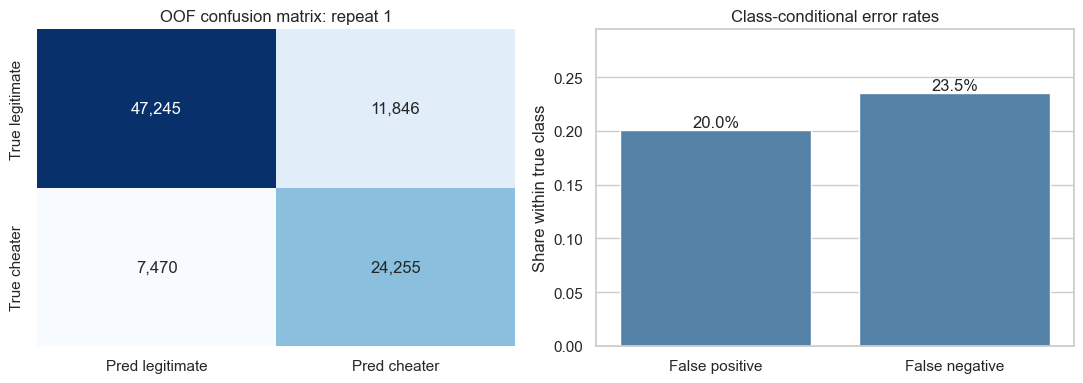

In [3]:
cm = confusion_matrix(oof1.true, oof1.pred, labels=[0, 1])
error_counts = oof1.error_type.value_counts().reindex(["TN", "FP", "FN", "TP"])
fp_rate = cm[0, 1] / cm[0].sum()
fn_rate = cm[1, 0] / cm[1].sum()
display(error_counts.rename("accounts").to_frame())
print(f"False-positive rate among legitimate: {fp_rate:.2%}")
print(f"False-negative rate among cheaters: {fn_rate:.2%}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=["Pred legitimate", "Pred cheater"],
            yticklabels=["True legitimate", "True cheater"])
axes[0].set_title("OOF confusion matrix: repeat 1")
rates = pd.DataFrame({"error": ["False positive", "False negative"],
                      "rate": [fp_rate, fn_rate]})
sns.barplot(data=rates, x="error", y="rate", color="steelblue", ax=axes[1])
axes[1].set_ylim(0, max(rates.rate) * 1.25)
axes[1].set_ylabel("Share within true class")
axes[1].set_xlabel("")
axes[1].set_title("Class-conditional error rates")
for bar, value in zip(axes[1].patches, rates.rate):
    axes[1].annotate(f"{value:.1%}", (bar.get_x()+bar.get_width()/2, bar.get_height()),
                     ha="center", va="bottom")
plt.tight_layout()
plt.show()

## 3. Probability and threshold geometry

Each fold has its own threshold, so `prob - threshold` is the comparable decision margin. Large positive margins on legitimate accounts and large negative margins on cheaters are confident mistakes.

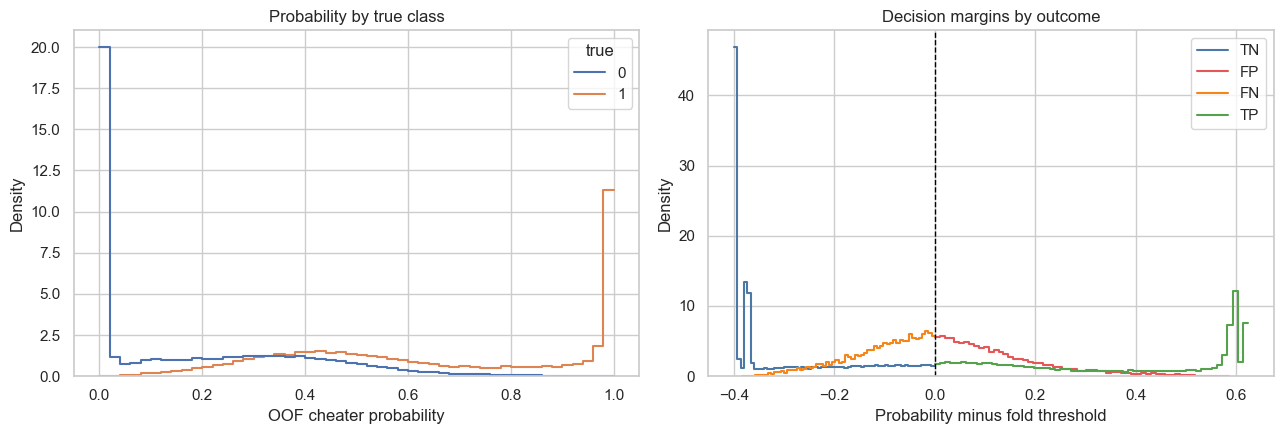

,type,condition,accounts
0,FP,p >= 0.8,327
1,FN,p <= 0.1,191
2,FP,margin >= 0.2,2541
3,FN,margin <= -0.2,1111


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(data=oof1, x="prob", hue="true", hue_order=[0, 1],
             bins=50, stat="density", common_norm=False, element="step",
             fill=False, ax=axes[0])
axes[0].set(xlabel="OOF cheater probability", title="Probability by true class")
for kind, color in [("TN", "#4c78a8"), ("FP", "#e45756"),
                    ("FN", "#f58518"), ("TP", "#54a24b")]:
    sns.histplot(oof1.loc[oof1.error_type == kind, "margin"], bins=60,
                 stat="density", element="step", fill=False,
                 label=kind, color=color, ax=axes[1])
axes[1].axvline(0, color="black", linestyle="--", linewidth=1)
axes[1].set(xlabel="Probability minus fold threshold", title="Decision margins by outcome")
axes[1].legend()
plt.tight_layout()
plt.show()

confidence = pd.DataFrame([
    {"type": "FP", "condition": "p >= 0.8", "accounts": int(((oof1.error_type == "FP") & (oof1.prob >= 0.8)).sum())},
    {"type": "FN", "condition": "p <= 0.1", "accounts": int(((oof1.error_type == "FN") & (oof1.prob <= 0.1)).sum())},
    {"type": "FP", "condition": "margin >= 0.2", "accounts": int(((oof1.error_type == "FP") & (oof1.margin >= 0.2)).sum())},
    {"type": "FN", "condition": "margin <= -0.2", "accounts": int(((oof1.error_type == "FN") & (oof1.margin <= -0.2)).sum())},
])
display(confidence)

## 4. Are mistakes stable across folds?

The two repeats validate each account with a different partition, but reuse the same labeled data. Agreement identifies hard cases; it does not supply an independent test set.

error_type_r2,TN,FP,FN,TP
error_type_r1,,,,
TN,44917,2328,0,0
FP,1698,10148,0,0
FN,0,0,5955,1515
TP,0,0,1155,23100


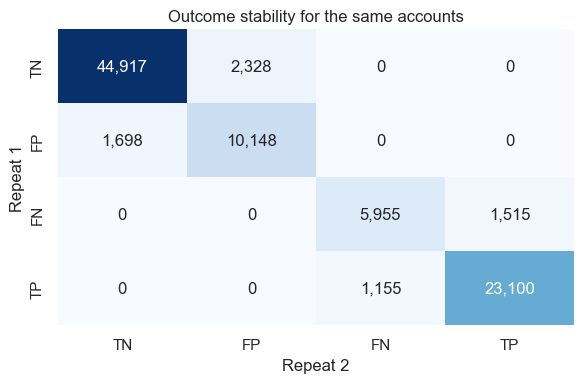

FP in both repeats: 10,148 of 11,846 repeat-1 cases (85.7%)
FN in both repeats: 5,955 of 7,470 repeat-1 cases (79.7%)


In [5]:
paired = oof1[["row_index", "true", "error_type", "prob", "margin"]].merge(
    oof2[["row_index", "error_type", "prob", "margin"]], on="row_index",
    suffixes=("_r1", "_r2"), validate="one_to_one")
assert paired.true.equals(oof1.true)
stability = pd.crosstab(paired.error_type_r1, paired.error_type_r2).reindex(
    index=["TN", "FP", "FN", "TP"], columns=["TN", "FP", "FN", "TP"], fill_value=0)
display(stability)
fig, ax = plt.subplots(figsize=(6, 4))
sns.heatmap(stability, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax)
ax.set(xlabel="Repeat 2", ylabel="Repeat 1", title="Outcome stability for the same accounts")
plt.tight_layout()
plt.show()
for kind in ("FP", "FN"):
    n1 = (paired.error_type_r1 == kind).sum()
    both = ((paired.error_type_r1 == kind) & (paired.error_type_r2 == kind)).sum()
    print(f"{kind} in both repeats: {both:,} of {n1:,} repeat-1 cases ({both/n1:.1%})")

## 5. One-dimensional error slices

These plots describe where false positives and false negatives concentrate. Bins use quantiles of the labeled Train data, and the rate denominator is the true class *within that bin*. Missing values get their own bin. The dashed line is the class-wide error rate. Thin or empty bins should not be interpreted as evidence.

,bin,true,accounts,error_rate,feature
0,"(3.999, 8.0]",0,8029,0.3536,reports_received
1,"(8.0, 11.0]",0,8171,0.3129,reports_received
2,"(11.0, 14.0]",0,8691,0.2994,reports_received
3,"(14.0, 17.0]",0,8468,0.1107,reports_received
4,"(17.0, 29.0]",0,12527,0.0097,reports_received
5,Missing,0,13205,0.2112,reports_received
6,"(3.999, 8.0]",1,8734,0.1356,reports_received
7,"(8.0, 11.0]",1,5934,0.1933,reports_received
8,"(11.0, 14.0]",1,6027,0.2104,reports_received
9,"(14.0, 17.0]",1,2935,0.3601,reports_received


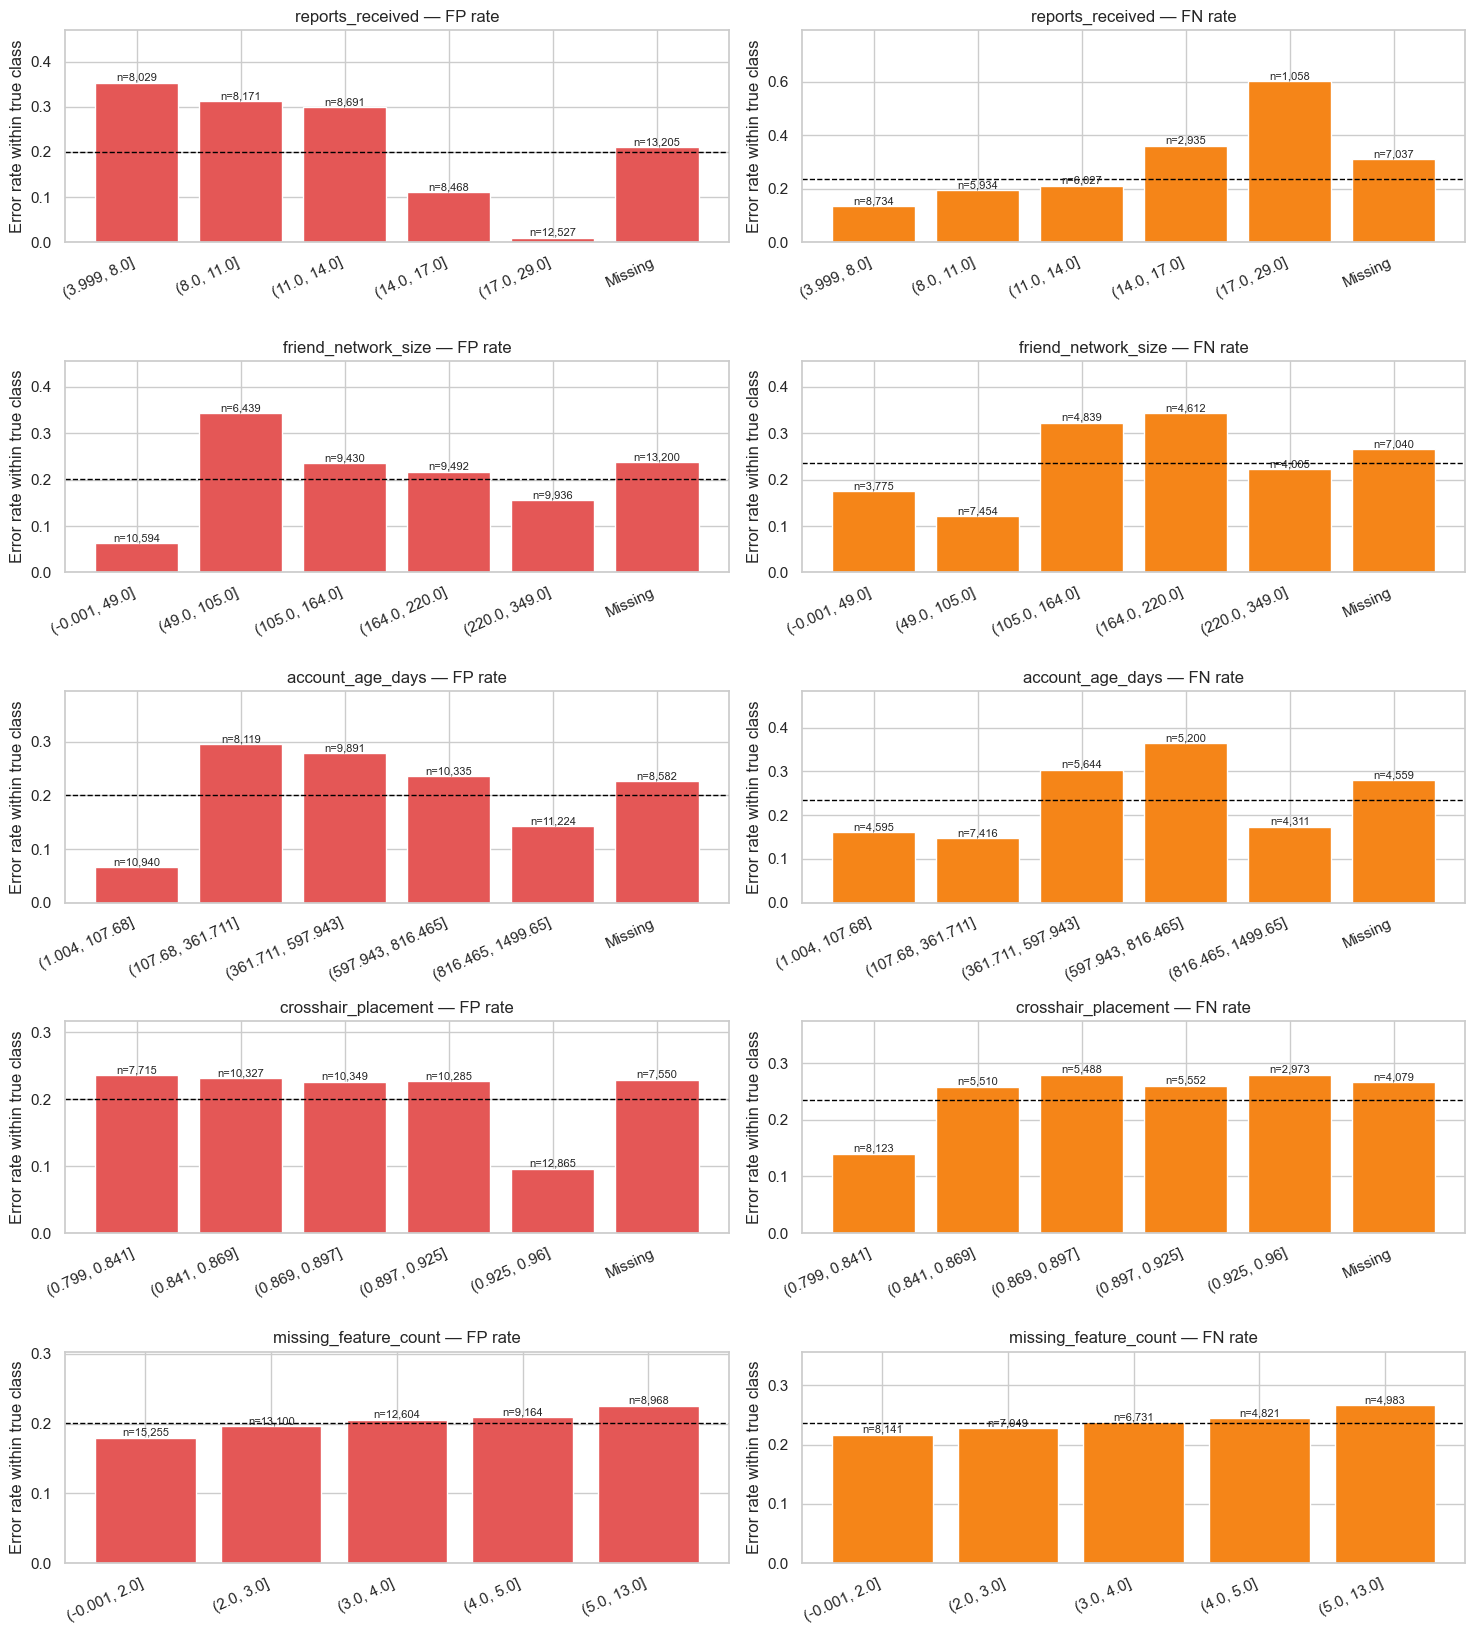

In [6]:
audit = train.copy().reset_index(drop=True)
audit["true"] = oof1.true
audit["pred"] = oof1.pred
audit["prob"] = oof1.prob
audit["error_type"] = oof1.error_type

FEATURES = ["reports_received", "friend_network_size", "account_age_days",
            "crosshair_placement", "missing_feature_count"]

def slice_table(frame, feature, q=5):
    values = frame[feature]
    nonmissing = values.dropna()
    if nonmissing.nunique() <= q:
        bins = values.astype("string").fillna("Missing")
        order = [str(x) for x in sorted(nonmissing.unique())] + (["Missing"] if values.isna().any() else [])
    else:
        cut = pd.qcut(values, q=q, duplicates="drop")
        bins = cut.astype("string").fillna("Missing")
        order = [str(interval) for interval in cut.cat.categories]
        if values.isna().any():
            order.append("Missing")
    work = pd.DataFrame({"bin": bins, "true": frame.true, "wrong": frame.true != frame.pred})
    rows = work.groupby(["bin", "true"], observed=True).agg(
        accounts=("wrong", "size"), error_rate=("wrong", "mean")).reset_index()
    rows["feature"] = feature
    rows["bin"] = pd.Categorical(rows["bin"], categories=order, ordered=True)
    return rows.sort_values(["true", "bin"])

slice_results = pd.concat([slice_table(audit, feature) for feature in FEATURES], ignore_index=True)
display(slice_results.round(4))

fig, axes = plt.subplots(len(FEATURES), 2, figsize=(15, 3.3 * len(FEATURES)))
for i, feature in enumerate(FEATURES):
    table = slice_results[slice_results.feature == feature]
    for label, baseline, ax in [(0, fp_rate, axes[i, 0]), (1, fn_rate, axes[i, 1])]:
        part = table[table.true == label].copy()
        x = np.arange(len(part))
        bars = ax.bar(x, part.error_rate, color="#e45756" if label == 0 else "#f58518")
        ax.axhline(baseline, color="black", linestyle="--", linewidth=1)
        ax.set_xticks(x, part["bin"].astype(str), rotation=25, ha="right")
        ax.set_ylim(0, max(part.error_rate.max(), baseline) * 1.3 + 0.01)
        ax.set_ylabel("Error rate within true class")
        ax.set_title(f"{feature} — {'FP' if label == 0 else 'FN'} rate")
        for bar, n in zip(bars, part.accounts):
            ax.annotate(f"n={n:,}", (bar.get_x()+bar.get_width()/2, bar.get_height()),
                        ha="center", va="bottom", fontsize=8)
plt.tight_layout()
plt.show()

## 6. Two-feature error maps

Show class-conditional error rates for two pairs of existing inputs. Each cell is annotated with its number of true-class accounts; cells with fewer than 200 are blanked. Quantile bins are descriptive and selected from labeled Train. This is a way to locate patterns, not an estimate of feature importance or causation.

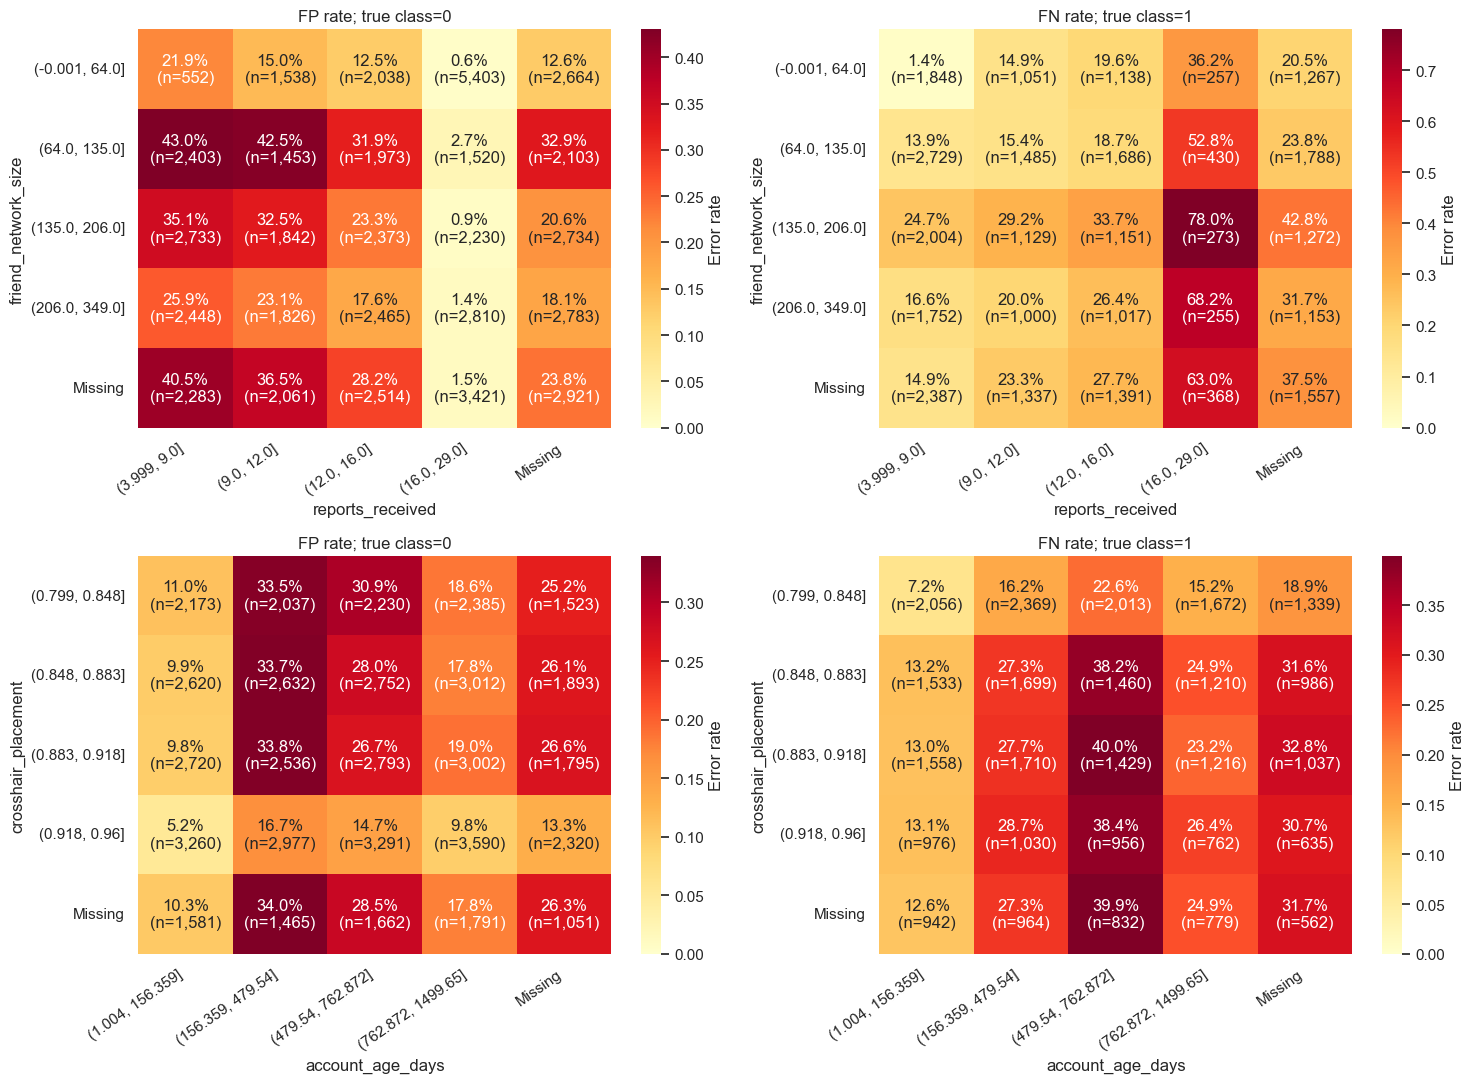

In [7]:
def quantile_labels(values, q=4):
    if values.dropna().nunique() <= 1:
        return values.astype("string").fillna("Missing")
    cut = pd.qcut(values, q=q, duplicates="drop")
    return cut.cat.add_categories("Missing").fillna("Missing")

PAIRS = [("reports_received", "friend_network_size"),
         ("account_age_days", "crosshair_placement")]
fig, axes = plt.subplots(len(PAIRS), 2, figsize=(15, 11))
for row, (x_feature, y_feature) in enumerate(PAIRS):
    xbin, ybin = quantile_labels(audit[x_feature]), quantile_labels(audit[y_feature])
    for col, true_label in enumerate((0, 1)):
        sub = pd.DataFrame({"x": xbin, "y": ybin,
                            "wrong": audit.true != audit.pred}).loc[audit.true == true_label]
        agg = sub.groupby(["y", "x"], observed=True).wrong.agg(["size", "mean"]).reset_index()
        rates = agg.pivot(index="y", columns="x", values="mean")
        counts = agg.pivot(index="y", columns="x", values="size").reindex_like(rates)
        rates = rates.where(counts >= 200)
        labels = rates.copy().astype(object)
        for yi in range(len(rates.index)):
            for xi in range(len(rates.columns)):
                value = rates.iloc[yi, xi]
                labels.iat[yi, xi] = f"{value:.1%}\n(n={int(counts.iloc[yi, xi]):,})" if pd.notna(value) else ""
        sns.heatmap(rates, annot=labels, fmt="", cmap="YlOrRd", vmin=0,
                    cbar_kws={"label": "Error rate"}, ax=axes[row, col])
        axes[row, col].set(xlabel=x_feature, ylabel=y_feature,
                           title=f"{'FP' if true_label == 0 else 'FN'} rate; true class={true_label}")
        axes[row, col].tick_params(axis="x", labelrotation=35)
        for tick in axes[row, col].get_xticklabels(): tick.set_ha("right")
        axes[row, col].tick_params(axis="y", labelrotation=0)
plt.tight_layout()
plt.show()

## 7. Check slice patterns in repeat 2

The same bins apply because both repeats contain the same accounts. This checks whether the observed error slices persist across fitted fold models; it is not an independent sample.

,feature,bin,true,accounts_r1,error_rate_r1,error_rate_r2,excess_r1,excess_r2
10,reports_received,"(17.0, 29.0]",1,1058,0.6011,0.5907,0.3657,0.3666
0,reports_received,"(3.999, 8.0]",0,8029,0.3536,0.3697,0.1531,0.1585
13,friend_network_size,"(49.0, 105.0]",0,6439,0.3432,0.3653,0.1428,0.1541
33,account_age_days,"(597.943, 816.465]",1,5200,0.3642,0.3396,0.1288,0.1155
9,reports_received,"(14.0, 17.0]",1,2935,0.3601,0.3526,0.1247,0.1285
1,reports_received,"(8.0, 11.0]",0,8171,0.3129,0.3270,0.1125,0.1159
21,friend_network_size,"(164.0, 220.0]",1,4612,0.3430,0.3207,0.1076,0.0966
2,reports_received,"(11.0, 14.0]",0,8691,0.2994,0.3161,0.0989,0.1049
25,account_age_days,"(107.68, 361.711]",0,8119,0.2954,0.3092,0.0949,0.0980
20,friend_network_size,"(105.0, 164.0]",1,4839,0.3226,0.3038,0.0871,0.0797


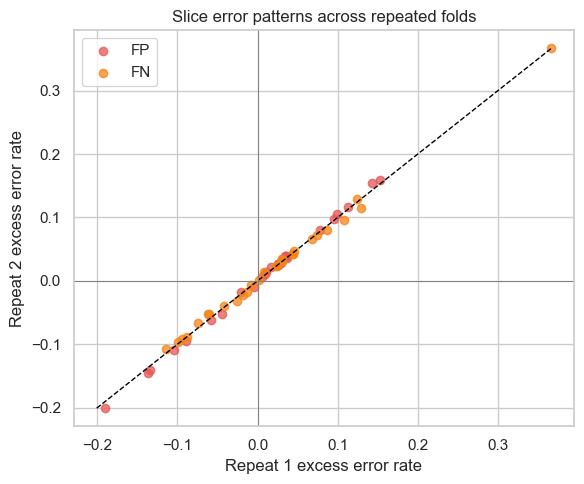

In [8]:
audit2 = audit.copy()
audit2["pred"] = oof2.pred
slice_results2 = pd.concat([slice_table(audit2, feature) for feature in FEATURES], ignore_index=True)
repeat_compare = slice_results.merge(
    slice_results2, on=["feature", "bin", "true"], suffixes=("_r1", "_r2"),
    validate="one_to_one")
assert (repeat_compare.accounts_r1 == repeat_compare.accounts_r2).all()
fp_rate2 = ((oof2.true == 0) & (oof2.pred == 1)).sum() / (oof2.true == 0).sum()
fn_rate2 = ((oof2.true == 1) & (oof2.pred == 0)).sum() / (oof2.true == 1).sum()
repeat_compare["excess_r1"] = repeat_compare.error_rate_r1 - np.where(repeat_compare.true == 0, fp_rate, fn_rate)
repeat_compare["excess_r2"] = repeat_compare.error_rate_r2 - np.where(repeat_compare.true == 0, fp_rate2, fn_rate2)
top_slices = (repeat_compare.loc[repeat_compare.accounts_r1 >= 1000]
              .sort_values("excess_r1", ascending=False)
              [["feature", "bin", "true", "accounts_r1", "error_rate_r1",
                "error_rate_r2", "excess_r1", "excess_r2"]].head(15))
display(top_slices.round(4))

fig, ax = plt.subplots(figsize=(6, 5))
for label, color in [(0, "#e45756"), (1, "#f58518")]:
    part = repeat_compare[(repeat_compare.true == label) & (repeat_compare.accounts_r1 >= 1000)]
    ax.scatter(part.excess_r1, part.excess_r2, label="FP" if label == 0 else "FN",
               alpha=.75, color=color)
limits = [min(repeat_compare.excess_r1.min(), repeat_compare.excess_r2.min()),
          max(repeat_compare.excess_r1.max(), repeat_compare.excess_r2.max())]
ax.plot(limits, limits, color="black", linestyle="--", linewidth=1)
ax.axhline(0, color="gray", linewidth=.7)
ax.axvline(0, color="gray", linewidth=.7)
ax.set(xlabel="Repeat 1 excess error rate", ylabel="Repeat 2 excess error rate",
       title="Slice error patterns across repeated folds")
ax.legend()
plt.tight_layout()
plt.show()

## 8. How common are raw-feature outliers?

The flag below uses Tukey's 1.5×IQR fences on the **31 raw predictors**, calculated from labeled Train for this descriptive audit. It does not use the target, Test, or engineered columns. A flagged extreme value can be valid gameplay; this is a statistical tail definition, not a data-error verdict. Missing values are counted separately and never silently labeled as outliers.

,feature,observed,missing_pct,iqr_outliers,iqr_outlier_pct_all_rows,lower_fence,upper_fence
8,level_progression_speed,83437,8.125,11687,12.869,-0.219,0.474
0,kill_death_ratio,82093,9.605,2149,2.366,0.978,8.275
5,reaction_time_ms,83675,7.863,2077,2.287,5.051,257.039
10,reports_received,70574,22.289,1497,1.648,-1.500,26.500
1,headshot_percentage,88325,2.743,960,1.057,10.732,84.182
3,accuracy_score,90265,0.607,610,0.672,7.113,72.699
18,aiming_smoothness,71914,20.814,346,0.381,0.512,1.168
12,input_consistency_score,81955,9.757,293,0.323,0.457,1.034
19,spray_control_score,75612,16.742,236,0.260,0.460,1.134
20,game_sense_score,88423,2.635,197,0.217,0.533,1.109


At least one raw-feature IQR outlier: 17,532/90,816 (19.30%)
Three or more raw-feature IQR outliers: 243


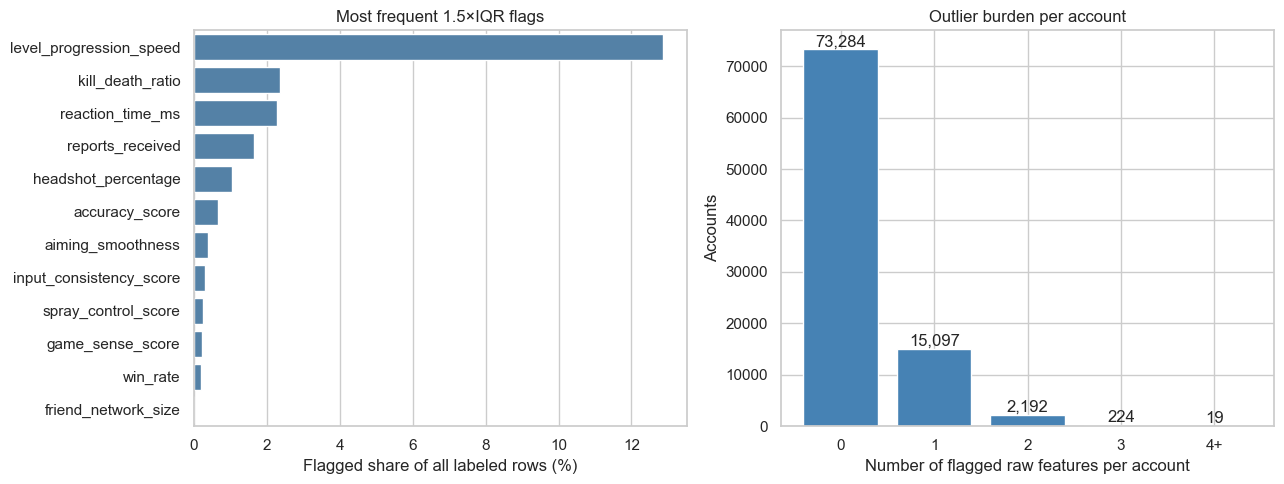

In [9]:
raw_columns = [c for c in train.columns if c in data_card["splits"]["test"]["columns"]
               and c not in (ID, TARGET) and c not in
               ["missing_feature_count", "account_age_days_missing", "reports_received_missing",
                "avg_session_length_min_missing", "aiming_smoothness_missing",
                "reports_per_100_days", "daily_play_hours", "headshot_accuracy_gap",
                "aim_precision_mean", "aim_precision_spread", "aim_precision_observed",
                "reaction_adjusted_aim", "aim_strategy_gap", "kd_per_teamplay"]]
assert len(raw_columns) == 31
q1, q3 = train[raw_columns].quantile(.25), train[raw_columns].quantile(.75)
iqr = q3 - q1
assert (iqr > 0).all()
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outlier_matrix = train[raw_columns].lt(lower) | train[raw_columns].gt(upper)
outlier_count = outlier_matrix.sum(axis=1)
audit["iqr_outlier_count"] = outlier_count
audit["any_iqr_outlier"] = outlier_count.gt(0)
feature_outliers = pd.DataFrame({
    "feature": raw_columns,
    "observed": train[raw_columns].notna().sum().to_numpy(),
    "missing_pct": (train[raw_columns].isna().mean() * 100).to_numpy(),
    "iqr_outliers": outlier_matrix.sum().to_numpy(),
    "iqr_outlier_pct_all_rows": (outlier_matrix.mean() * 100).to_numpy(),
    "lower_fence": lower.to_numpy(), "upper_fence": upper.to_numpy(),
}).sort_values("iqr_outliers", ascending=False)
display(feature_outliers.round(3))
print(f"At least one raw-feature IQR outlier: {audit.any_iqr_outlier.sum():,}/{len(audit):,} ({audit.any_iqr_outlier.mean():.2%})")
print(f"Three or more raw-feature IQR outliers: {(outlier_count >= 3).sum():,}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.barplot(data=feature_outliers.head(12), x="iqr_outlier_pct_all_rows", y="feature",
            color="steelblue", ax=axes[0])
axes[0].set(xlabel="Flagged share of all labeled rows (%)", ylabel="",
            title="Most frequent 1.5×IQR flags")
count_plot = outlier_count.clip(upper=4).value_counts().reindex(range(5), fill_value=0)
axes[1].bar(["0", "1", "2", "3", "4+"], count_plot.values, color="steelblue")
axes[1].set(xlabel="Number of flagged raw features per account", ylabel="Accounts",
            title="Outlier burden per account")
for i, value in enumerate(count_plot):
    axes[1].annotate(f"{value:,}", (i, value), ha="center", va="bottom")
plt.tight_layout()
plt.show()

## 9. Check obvious domain violations

Only constraints supported directly by the data card or the feature definition are checked. Scores without a documented hard range are not declared invalid. A zero count here rules out these simple violations, not all possible data-quality issues.

In [10]:
domain_bounds = {
    "headshot_percentage": (0, 100), "win_rate": (0, 100),
    "night_play_ratio": (0, 1), "clutch_success_rate": (0, 1),
    "first_blood_rate": (0, 1), "utility_usage_rate": (0, 1),
    "account_age_days": (0, np.inf), "friend_network_size": (0, np.inf),
    "reports_received": (0, np.inf), "device_changes_count": (0, np.inf),
    "reaction_time_ms": (0, np.inf), "sessions_per_day": (0, np.inf),
}
violations = pd.DataFrame([
    {"feature": feature, "allowed": f"[{lo}, {hi}]",
     "below": int(train[feature].lt(lo).sum()),
     "above": int(train[feature].gt(hi).sum()),
     "missing": int(train[feature].isna().sum())}
    for feature, (lo, hi) in domain_bounds.items()
])
display(violations)
print("Rows with any checked domain violation:",
      int(sum(train[f].lt(lo) | train[f].gt(hi) for f, (lo, hi) in domain_bounds.items()).gt(0).sum()))

,feature,allowed,below,above,missing
0,headshot_percentage,"[0, 100]",0,0,2491
1,win_rate,"[0, 100]",0,0,4495
2,night_play_ratio,"[0, 1]",0,0,7055
3,clutch_success_rate,"[0, 1]",0,0,2254
4,first_blood_rate,"[0, 1]",0,0,7056
5,utility_usage_rate,"[0, 1]",0,0,10103
6,account_age_days,"[0, inf]",0,0,13141
7,friend_network_size,"[0, inf]",0,0,20240
8,reports_received,"[0, inf]",0,0,20242
9,device_changes_count,"[0, inf]",0,0,2657


Rows with any checked domain violation: 0


## 10. Do outliers explain the errors near p≈0.38?

The outer folds chose thresholds of 0.375 or 0.400, so define the near-boundary region as `abs(prob - fold_threshold) <= 0.05`. The table reports each group's size and class-conditional error rate. The plot uses separate legitimate and cheater panels to avoid class mix distorting the comparison. This is association, not a causal decomposition into “data” and “model” error.

,near_boundary,any_iqr_outlier,accounts,errors,error_rate,cheater_share,share_of_all_errors
0,False,False,63129,12318,0.1951,0.3558,0.6377
1,False,True,16486,1629,0.0988,0.2904,0.0843
2,True,False,10155,4857,0.4783,0.4001,0.2514
3,True,True,1046,512,0.4895,0.3967,0.0265


,true,near_boundary,any_iqr_outlier,accounts,errors,error_rate
0,0,False,False,40670,7772,0.1911
1,0,False,True,11698,876,0.0749
2,0,True,False,6092,2900,0.4760
3,0,True,True,631,298,0.4723
4,1,False,False,22459,4546,0.2024
5,1,False,True,4788,753,0.1573
6,1,True,False,4063,1957,0.4817
7,1,True,True,415,214,0.5157


Outlier rows among all mistakes: 11.08%
Near-boundary rows among all mistakes: 27.80%


,repeat,errors,errors_in_iqr_outlier_rows,share_errors_in_outlier_rows,errors_near_boundary,share_errors_near_boundary
0,1,19316,2141,0.1108,5369,0.2780
1,2,19586,2204,0.1125,5470,0.2793


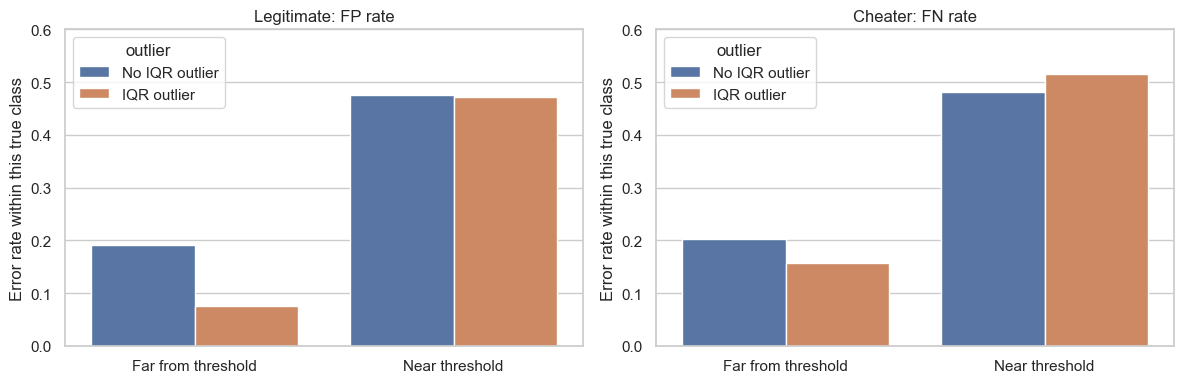

In [11]:
audit["near_boundary"] = oof1.margin.abs().le(.05)
audit["wrong"] = oof1.true.ne(oof1.pred)
summary = (audit.groupby(["near_boundary", "any_iqr_outlier"], observed=True)
           .agg(accounts=("wrong", "size"), errors=("wrong", "sum"),
                error_rate=("wrong", "mean"), cheater_share=("true", "mean"))
           .reset_index())
summary["share_of_all_errors"] = summary.errors / audit.wrong.sum()
display(summary.round(4))

class_summary = (audit.groupby(["true", "near_boundary", "any_iqr_outlier"], observed=True)
                 .agg(accounts=("wrong", "size"), errors=("wrong", "sum"),
                      error_rate=("wrong", "mean")).reset_index())
display(class_summary.round(4))
print("Outlier rows among all mistakes:",
      f"{audit.loc[audit.wrong, 'any_iqr_outlier'].mean():.2%}")
print("Near-boundary rows among all mistakes:",
      f"{audit.loc[audit.wrong, 'near_boundary'].mean():.2%}")

repeat_check = []
for repeat, frame in [(1, oof1), (2, oof2)]:
    wrong = frame.true.ne(frame.pred)
    near = frame.margin.abs().le(.05)
    repeat_check.append({"repeat": repeat, "errors": int(wrong.sum()),
                         "errors_in_iqr_outlier_rows": int((wrong & audit.any_iqr_outlier).sum()),
                         "share_errors_in_outlier_rows": (wrong & audit.any_iqr_outlier).sum() / wrong.sum(),
                         "errors_near_boundary": int((wrong & near).sum()),
                         "share_errors_near_boundary": (wrong & near).sum() / wrong.sum()})
display(pd.DataFrame(repeat_check).round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for true_label, ax in zip((0, 1), axes):
    part = class_summary[class_summary.true == true_label].copy()
    part["region"] = np.where(part.near_boundary, "Near threshold", "Far from threshold")
    part["outlier"] = np.where(part.any_iqr_outlier, "IQR outlier", "No IQR outlier")
    sns.barplot(data=part, x="region", y="error_rate", hue="outlier", ax=ax)
    ax.set(xlabel="", ylabel="Error rate within this true class",
           title="Legitimate: FP rate" if true_label == 0 else "Cheater: FN rate",
           ylim=(0, .6))
plt.tight_layout()
plt.show()

## 11. Error rate by outlier count and absolute distance from the threshold

The IQR rule flags `level_progression_speed` frequently, so raw outlier counts should not be read as severity. Absolute margin measures distance from each fold's threshold on either side; its error rate is not predetermined by the sign of the decision. The bins are descriptive; moving the decision threshold based on these validation labels would give an optimistic score.

,true,outlier_group,accounts,error_rate
0,0,0,46762,0.2282
1,0,1,10219,0.1078
2,0,2,1885,0.0355
3,0,3+,225,0.0222
4,1,0,26522,0.2452
5,1,1,4878,0.1839
6,1,2,307,0.2182
7,1,3+,18,0.1667


,true,distance_bin,accounts,error_rate
0,0,"(-1.0, 0.025]",3476,0.4819
1,0,"(0.025, 0.05]",3247,0.4690
2,0,"(0.05, 0.1]",6340,0.4192
3,0,"(0.1, 0.2]",10060,0.3428
4,0,"(0.2, 0.3]",7483,0.2002
5,0,"(0.3, inf]",28485,0.0366
6,1,"(-1.0, 0.025]",2266,0.5004
7,1,"(0.025, 0.05]",2212,0.4688
8,1,"(0.05, 0.1]",4109,0.4471
9,1,"(0.1, 0.2]",6087,0.3862


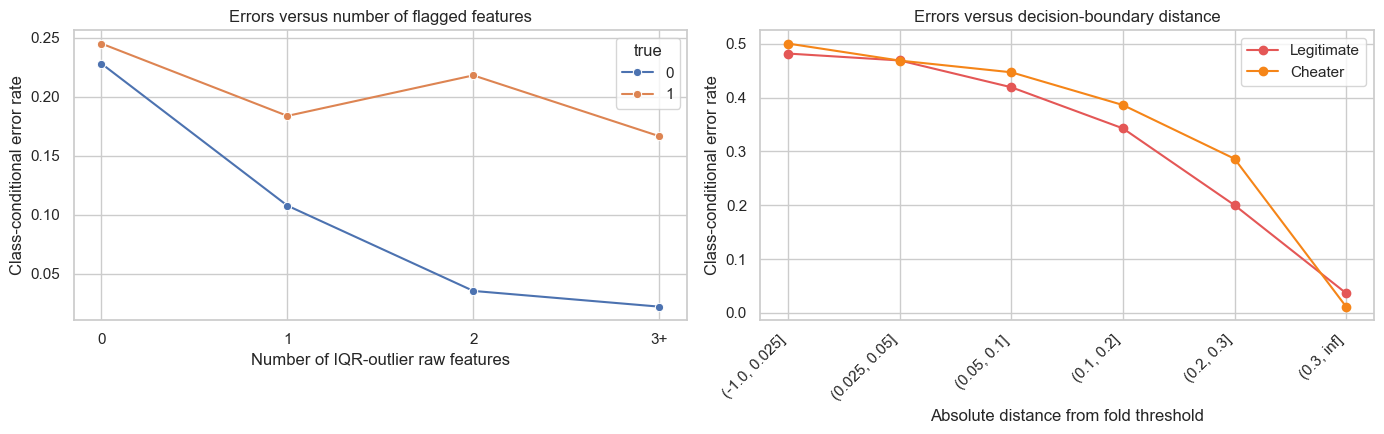

In [12]:
audit["outlier_group"] = pd.cut(audit.iqr_outlier_count,
                                bins=[-1, 0, 1, 2, np.inf],
                                labels=["0", "1", "2", "3+"])
outlier_error = (audit.groupby(["true", "outlier_group"], observed=True)
                 .agg(accounts=("wrong", "size"), error_rate=("wrong", "mean"))
                 .reset_index())
display(outlier_error.round(4))

distance_edges = [-1, .025, .05, .1, .2, .3, np.inf]
audit["distance_bin"] = pd.cut(oof1.margin.abs(), bins=distance_edges)
distance_error = (audit.groupby(["true", "distance_bin"], observed=True)
                .agg(accounts=("wrong", "size"), error_rate=("wrong", "mean"))
                .reset_index())
display(distance_error.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.lineplot(data=outlier_error, x="outlier_group", y="error_rate", hue="true",
             marker="o", ax=axes[0])
axes[0].set(xlabel="Number of IQR-outlier raw features", ylabel="Class-conditional error rate",
            title="Errors versus number of flagged features")
for label, color in [(0, "#e45756"), (1, "#f58518")]:
    part = distance_error[distance_error.true == label]
    axes[1].plot(np.arange(len(part)), part.error_rate, marker="o",
                 label="Legitimate" if label == 0 else "Cheater", color=color)
axes[1].set_xticks(np.arange(len(part)), part.distance_bin.astype(str), rotation=45, ha="right")
axes[1].set(xlabel="Absolute distance from fold threshold", ylabel="Class-conditional error rate",
            title="Errors versus decision-boundary distance")
axes[1].legend()
plt.tight_layout()
plt.show()

## Interpretation

Compare error rates and denominators before drawing conclusions. An IQR flag marks rarity under a univariate rule; it does not establish corrupted data. Errors outside flagged rows and outside the narrow decision band still require explanation. This audit cannot assign a percentage of mistakes causally to data versus model choice without an intervention such as verified label review or a paired model experiment. No training, feature engineering, Test access, or artifact writes occur here.